# Análise Estatística — Apenas Bases de Dados Reais

Este notebook filtra **exclusivamente as bases de dados reais** (ex.: `Elec2`, `CreditCard`, etc.) a partir dos resultados gerados por `scripts/run_de_deto_dase.py` (`runs.csv`, `events.csv` e `curves.npz`), mantendo o notebook `analise_de_deto_dase.ipynb` intacto para comparação.

Conteúdo:
1. **Tabela comparativa detalhada** (média ± desvio, mediana e IQR de Macro-F1, Acurácia, Kappa e Macro-F1 em janela);
2. **Ranking visual e distribuição entre sementes** (barras com erro e boxplots com pontos individuais);
3. **Testes estatísticos com todos os baselines** (Friedman + Nemenyi com Diagramas CD, Wilcoxon pareado + correção de Holm + tamanho de efeito $\hat{A}_{12}$ e matriz de $\hat{A}_{12}$);
4. **Curvas temporais** de Macro-F1 ao longo das streams reais;
5. **Custo computacional, eventos de drift e convergência pós-drift** nas bases reais.

In [2]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.stats import a12, a12_label, cd_diagram, friedman_nemenyi, holm, wilcoxon_p

# Diretório dos resultados (ajuste conforme a rodada que deseja analisar)
RESULTS_DIR = PROJECT_ROOT / "results" / "de_dase_nmin500"
FIG_DIR = RESULTS_DIR / "figures_reais"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Filtra automaticamente todas as bases que NÃO são sintéticas (ex.: Elec2, CreditCard, INSECTS)
SYNTH_DATASETS = {"SEA-Rec", "STAGGER-Rec", "AGR-Abr", "AGR-Grad", "RBF-Inc"}
CURVE_STEP = 100

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

runs_all = pd.read_csv(RESULTS_DIR / "runs.csv")
real_datasets = sorted([d for d in runs_all["dataset"].unique() if d not in SYNTH_DATASETS])
if not real_datasets:
    raise ValueError(f"Nenhuma base real encontrada em {RESULTS_DIR / 'runs.csv'}.")

runs = runs_all[runs_all["dataset"].isin(real_datasets)].copy()
core = runs[~runs["block"].isin(["detector", "sensitivity"])].copy()

events_all = pd.read_csv(RESULTS_DIR / "events.csv") if (RESULTS_DIR / "events.csv").exists() else pd.DataFrame()
events = events_all[events_all["dataset"].isin(real_datasets)].copy() if not events_all.empty else pd.DataFrame()
curves = np.load(RESULTS_DIR / "curves.npz") if (RESULTS_DIR / "curves.npz").exists() else {}

print(f"Bases reais encontradas: {real_datasets}")
print(f"Execuções (core): {len(core)} | Eventos: {len(events)} | Sementes: {core['seed'].nunique()}")
print("Métodos:", list(core["method"].unique()))

Bases reais encontradas: ['Elec2']
Execuções (core): 570 | Eventos: 6058 | Sementes: 30
Métodos: ['DE-S1', 'DE-S2', 'DE-S3', 'DE-S4', 'DE-S5', 'DE-S6', 'GA-S1', 'GA-S2', 'GA-S3', 'GA-S4', 'GA-S5', 'GA-S6', 'DASE', 'B1', 'B3', 'B4', 'B5', 'B6', 'B7']


## 1. Estatísticas Descritivas nas Bases Reais

In [3]:
def real_summary_table(df: pd.DataFrame, metric: str = "macro_f1") -> pd.DataFrame:
    g = df.groupby("method")[metric]
    out = pd.DataFrame({
        "Média": g.mean(),
        "Desvio": g.std(),
        "Mediana": g.median(),
        "IQR": g.quantile(0.75) - g.quantile(0.25),
        "Mín": g.min(),
        "Máx": g.max(),
    }).sort_values("Média", ascending=False)
    return out

for ds in real_datasets:
    print(f"=== {ds} — Macro-F1 Prequencial ===")
    display(real_summary_table(core[core["dataset"] == ds], "macro_f1").round(4))

if len(real_datasets) > 1:
    print("=== Média Geral (todas as bases reais) — Macro-F1 ===")
    display(real_summary_table(core, "macro_f1").round(4))

=== Elec2 — Macro-F1 Prequencial ===


,Média,Desvio,Mediana,IQR,Mín,Máx
method,,,,,,
GA-S5,0.8704,0.0025,0.8703,0.0029,0.8643,0.8745
GA-S2,0.8701,0.0030,0.8703,0.0059,0.8653,0.8748
GA-S6,0.8700,0.0028,0.8696,0.0039,0.8644,0.8755
GA-S3,0.8700,0.0027,0.8703,0.0039,0.8649,0.8748
DE-S4,0.8694,0.0027,0.8693,0.0037,0.8643,0.8734
DE-S3,0.8693,0.0026,0.8701,0.0035,0.8639,0.8745
DE-S6,0.8692,0.0026,0.8694,0.0022,0.8643,0.8735
GA-S4,0.8690,0.0025,0.8691,0.0038,0.8654,0.8737
GA-S1,0.8687,0.0028,0.8685,0.0033,0.8635,0.8750


In [4]:
# Comparativo consolidado de todas as métricas nas bases reais
metric_cols = [c for c in ["macro_f1", "accuracy", "kappa", "wf1_mean"] if c in core.columns]
metrics_tbl = core.groupby("method")[metric_cols].agg(["mean", "std"]).sort_values(("macro_f1", "mean"), ascending=False)
formatted = pd.DataFrame(index=metrics_tbl.index)
for c in metric_cols:
    formatted[c] = [
        f"{metrics_tbl.loc[m, (c, 'mean')]:.4f} ± {metrics_tbl.loc[m, (c, 'std')]:.4f}"
        for m in metrics_tbl.index
    ]
display(formatted)

,macro_f1,accuracy,kappa,wf1_mean
method,,,,
GA-S5,0.8704 ± 0.0025,0.8743 ± 0.0024,0.7409 ± 0.0050,0.8659 ± 0.0026
GA-S2,0.8701 ± 0.0030,0.8740 ± 0.0029,0.7403 ± 0.0060,0.8656 ± 0.0032
GA-S6,0.8700 ± 0.0028,0.8740 ± 0.0027,0.7402 ± 0.0055,0.8654 ± 0.0030
GA-S3,0.8700 ± 0.0027,0.8739 ± 0.0026,0.7401 ± 0.0053,0.8655 ± 0.0028
DE-S4,0.8694 ± 0.0027,0.8733 ± 0.0026,0.7389 ± 0.0053,0.8649 ± 0.0028
DE-S3,0.8693 ± 0.0026,0.8734 ± 0.0024,0.7388 ± 0.0051,0.8646 ± 0.0027
DE-S6,0.8692 ± 0.0026,0.8733 ± 0.0024,0.7385 ± 0.0051,0.8645 ± 0.0027
GA-S4,0.8690 ± 0.0025,0.8730 ± 0.0024,0.7382 ± 0.0050,0.8646 ± 0.0027
GA-S1,0.8687 ± 0.0028,0.8727 ± 0.0026,0.7375 ± 0.0055,0.8641 ± 0.0029


## 2. Comparação Visual: Ranking e Distribuição entre Sementes

Melhor DE (bases reais): DE-S4 (0.8694) | Melhor AG: GA-S5 (0.8704)


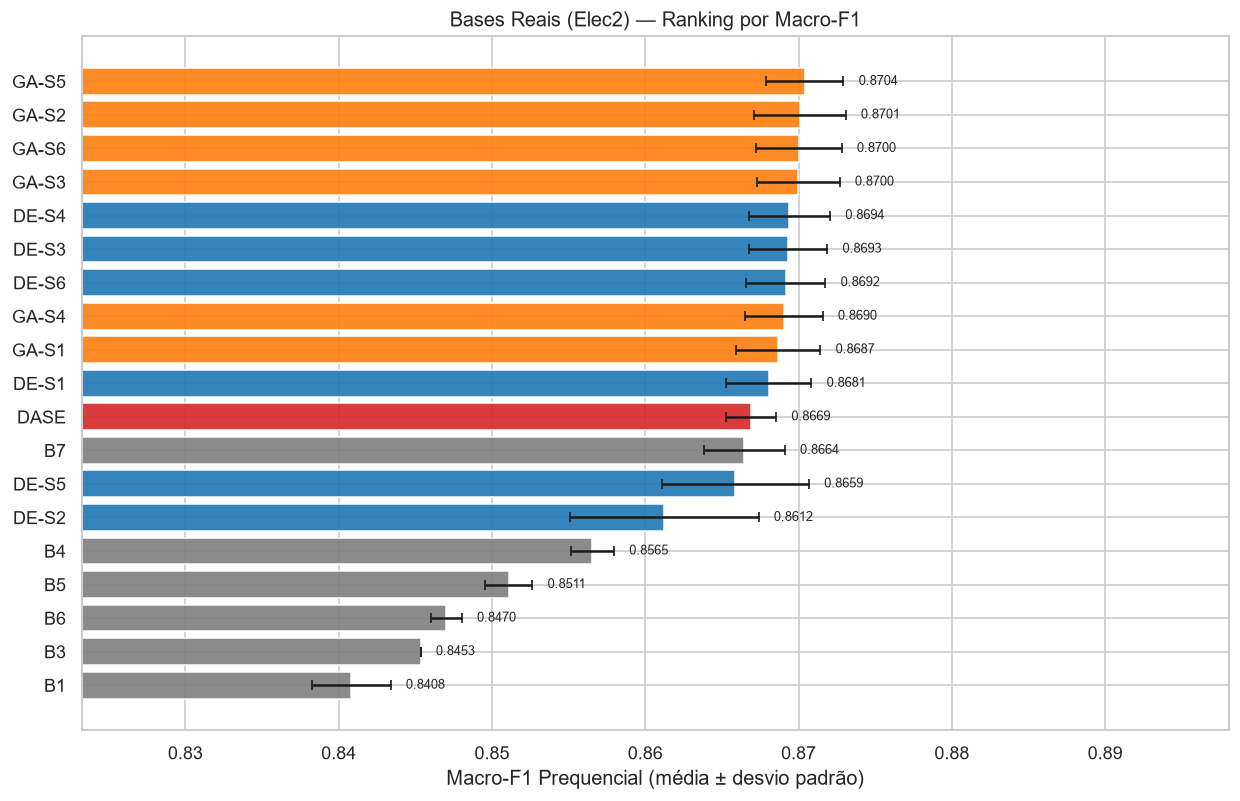

In [5]:
mean_by_method = core.groupby("method")["macro_f1"].mean()
std_by_method = core.groupby("method")["macro_f1"].std()

de_methods = sorted([m for m in mean_by_method.index if m.startswith("DE-")])
ga_methods = sorted([m for m in mean_by_method.index if m.startswith("GA-")])
baseline_methods = sorted([m for m in mean_by_method.index if m.startswith("B")])
bench_methods = [m for m in ("ARF", "SRP", "LeveragingBagging") if m in mean_by_method.index]
extra_methods = [m for m in ("DETO", "DASE") if m in mean_by_method.index]

best_de = mean_by_method[de_methods].idxmax() if de_methods else None
best_ga = mean_by_method[ga_methods].idxmax() if ga_methods else None
print(f"Melhor DE (bases reais): {best_de} ({mean_by_method[best_de]:.4f}) | Melhor AG: {best_ga} ({mean_by_method[best_ga]:.4f})")

order_asc = mean_by_method.sort_values(ascending=True).index
colors = [
    "#1f77b4" if m.startswith("DE-") else
    "#ff7f0e" if m.startswith("GA-") else
    "#2ca02c" if m == "DETO" else
    "#d62728" if m == "DASE" else
    "#7f7f7f"
    for m in order_asc
]

fig, ax = plt.subplots(figsize=(10.5, max(5.0, 0.36 * len(order_asc))))
ax.barh(order_asc, mean_by_method[order_asc], xerr=std_by_method[order_asc], color=colors, capsize=3, alpha=0.9)
for i, m in enumerate(order_asc):
    v = mean_by_method[m]
    ax.text(v + std_by_method[m] + 0.001, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlabel("Macro-F1 Prequencial (média ± desvio padrão)")
ax.set_title(f"Bases Reais ({', '.join(real_datasets)}) — Ranking por Macro-F1")
ax.set_xlim(max(0.0, (mean_by_method - std_by_method).min() - 0.015), min(1.0, (mean_by_method + std_by_method).max() + 0.025))
fig.tight_layout()
fig.savefig(FIG_DIR / "ranking_reais_macro_f1.png", dpi=150)
plt.show()

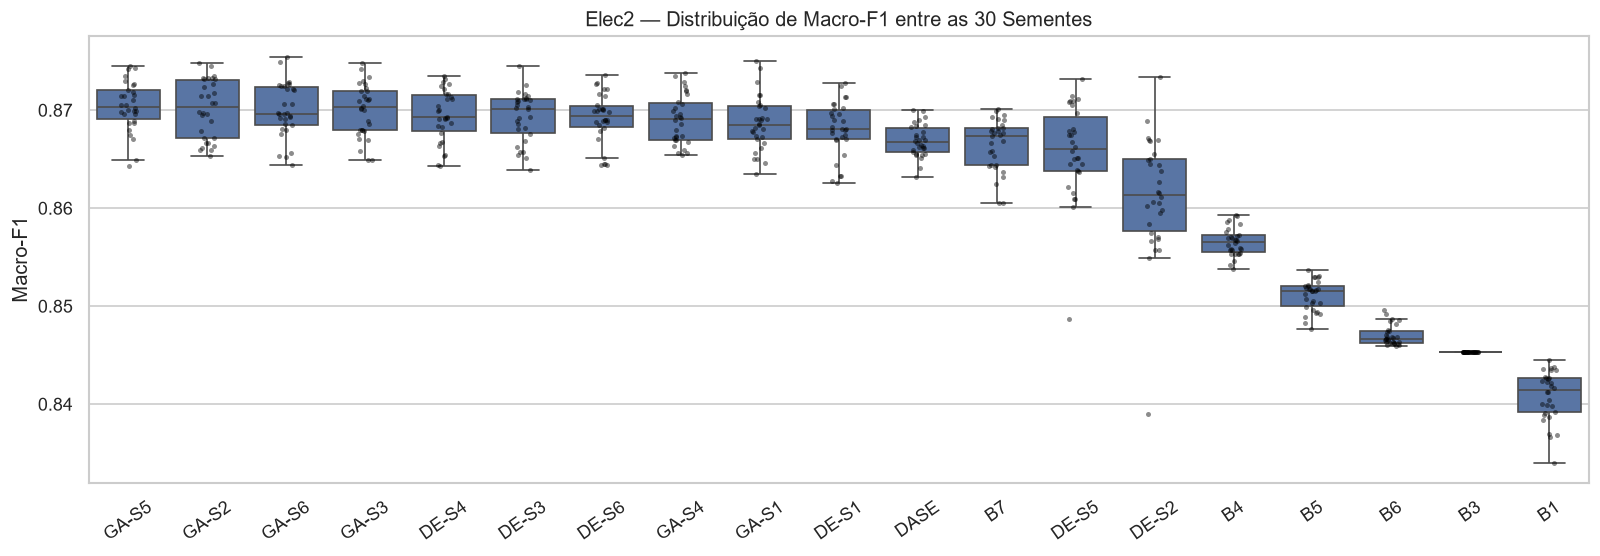

In [6]:
# Boxplot + pontos individuais das sementes por base real
order_desc = list(mean_by_method.sort_values(ascending=False).index)
for ds in real_datasets:
    df_ds = core[core["dataset"] == ds]
    fig, ax = plt.subplots(figsize=(13.5, 4.8))
    sns.boxplot(data=df_ds, x="method", y="macro_f1", order=order_desc, ax=ax, showfliers=False)
    sns.stripplot(data=df_ds, x="method", y="macro_f1", order=order_desc, ax=ax, color="black", size=3, alpha=0.45)
    ax.set_title(f"{ds} — Distribuição de Macro-F1 entre as {df_ds['seed'].nunique()} Sementes")
    ax.set_xlabel("")
    ax.set_ylabel("Macro-F1")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"boxplot_{ds}.png", dpi=150)
    plt.show()

## 3. Testes Estatísticos nas Bases Reais (Friedman + Nemenyi e Wilcoxon + Holm + $\hat{A}_{12}$)

=== Bases Reais (Elec2) — DE (S1–S6), Melhor AG, DETO/DASE e Baselines ===
Friedman p-valor = 9.3e-61 | CD (Nemenyi, α=0.05) = 3.623 | N = 30 blocos | k = 14 métodos


,Rank Médio
method,
GA-S5,2.833333
DE-S4,3.466667
DE-S3,3.800000
DE-S6,3.966667
DE-S1,4.766667
DE-S5,5.733333
DASE,6.200000
B7,6.333333
DE-S2,8.233333


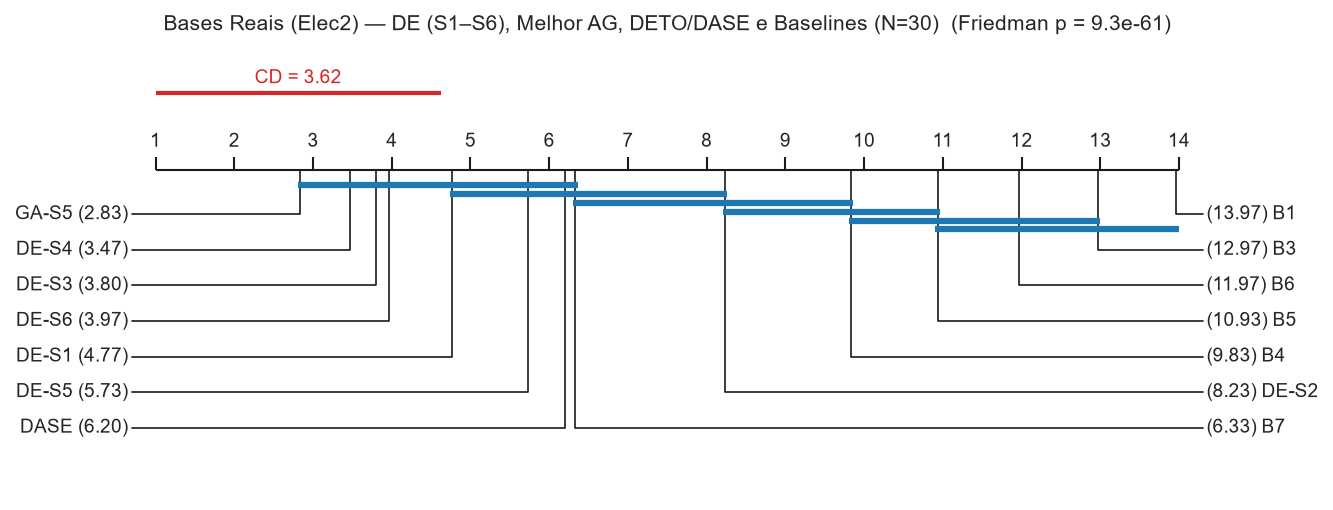

=== Bases Reais (Elec2) — Melhor DE vs Melhor AG vs DETO/DASE vs Baselines ===
Friedman p-valor = 6.625e-45 | CD (Nemenyi, α=0.05) = 2.193 | N = 30 blocos | k = 9 métodos


,Rank Médio
method,
GA-S5,1.666667
DE-S4,1.900000
DASE,3.166667
B7,3.266667
B4,5.000000
B5,6.000000
B6,7.000000
B3,8.000000
B1,9.000000


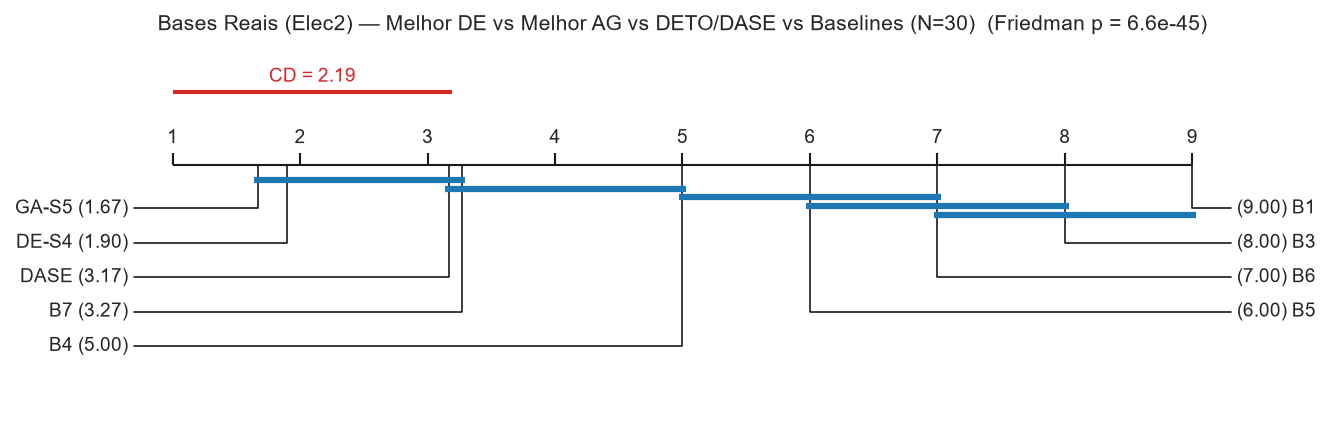

In [7]:
# Friedman + Nemenyi (blocos = (dataset, seed), incluindo todos os baselines)
cd_specs = [
    (
        "cd_reais_completo.png",
        f"Bases Reais ({', '.join(real_datasets)}) — DE (S1–S6), Melhor AG, DETO/DASE e Baselines",
        de_methods + ([best_ga] if best_ga else []) + extra_methods + baseline_methods + bench_methods,
    ),
    (
        "cd_reais_resumo.png",
        f"Bases Reais ({', '.join(real_datasets)}) — Melhor DE vs Melhor AG vs DETO/DASE vs Baselines",
        ([best_de] if best_de else []) + ([best_ga] if best_ga else []) + extra_methods + baseline_methods + bench_methods,
    ),
]

for fname, title, methods_list in cd_specs:
    methods_list = list(dict.fromkeys(methods_list))
    piv = core[core["method"].isin(methods_list)].pivot_table(
        index=["dataset", "seed"], columns="method", values="macro_f1"
    ).dropna()
    if len(piv) >= 3 and 3 <= len(methods_list) <= 20:
        fr = friedman_nemenyi(piv[methods_list])
        print(f"=== {title} ===")
        print(f"Friedman p-valor = {fr['p_value']:.4g} | CD (Nemenyi, α=0.05) = {fr['cd']:.3f} | N = {fr['N']} blocos | k = {fr['k']} métodos")
        display(fr["avg_ranks"].to_frame("Rank Médio"))
        cd_path = FIG_DIR / fname
        cd_diagram(fr["avg_ranks"], fr["cd"], f"{title} (N={fr['N']})", str(cd_path), fr["p_value"])
        display(Image(filename=str(cd_path)))
    else:
        print(f"Pulando {title}: N={len(piv)}, k={len(methods_list)}.")

In [8]:
# Wilcoxon pareado (sementes) + correção de Holm + Â12 nas bases reais
comps = []
if best_de:
    targets = ([best_ga] if best_ga else []) + extra_methods + baseline_methods + bench_methods
    for t in list(dict.fromkeys(targets)):
        if t and t != best_de:
            comps.append((best_de, t))
    if "DE-S1" in de_methods:
        for s in de_methods:
            if s != "DE-S1":
                comps.append((s, "DE-S1"))

w_rows = []
for ds in real_datasets:
    sub_ds = core[core["dataset"] == ds].pivot_table(index="seed", columns="method", values="macro_f1")
    valid_comps = [(a, b) for a, b in comps if a in sub_ds.columns and b in sub_ds.columns]
    if not valid_comps:
        continue
    pvals = [wilcoxon_p(sub_ds[a].dropna(), sub_ds[b].dropna()) for a, b in valid_comps]
    padj = holm(pvals)
    for (a, b), p, pa in zip(valid_comps, pvals, padj):
        xa, xb = sub_ds[a].dropna(), sub_ds[b].dropna()
        e = a12(xa, xb)
        diff = float(xa.mean() - xb.mean())
        res = "=" if pa >= 0.05 else ("+" if diff > 0 else "−")
        w_rows.append({
            "base": ds,
            "comparação": f"{a} vs {b}",
            "Δ macro-F1": diff,
            "p bruto": p,
            "p (Holm)": pa,
            "Â12": e,
            "efeito": a12_label(e),
            "resultado": res,
        })

wilcoxon_df = pd.DataFrame(w_rows)
display(wilcoxon_df)

,base,comparação,Δ macro-F1,p bruto,p (Holm),Â12,efeito,resultado
0,Elec2,DE-S4 vs GA-S5,-0.001009,1.980758e-01,3.213094e-01,0.395556,pequeno,=
1,Elec2,DE-S4 vs DASE,0.002507,1.060963e-05,6.365776e-05,0.775556,grande,+
2,Elec2,DE-S4 vs B1,0.028579,1.862645e-09,2.421439e-08,1.000000,grande,+
3,Elec2,DE-S4 vs B3,0.024053,1.862645e-09,2.421439e-08,1.000000,grande,+
4,Elec2,DE-S4 vs B4,0.012852,1.862645e-09,2.421439e-08,1.000000,grande,+
5,Elec2,DE-S4 vs B5,0.018302,1.862645e-09,2.421439e-08,1.000000,grande,+
6,Elec2,DE-S4 vs B6,0.022381,1.862645e-09,2.421439e-08,1.000000,grande,+
7,Elec2,DE-S4 vs B7,0.002943,2.762303e-06,1.933612e-05,0.783333,grande,+
8,Elec2,DE-S2 vs DE-S1,-0.006817,9.983778e-07,7.987022e-06,0.115556,grande,−
9,Elec2,DE-S3 vs DE-S1,0.001247,8.032736e-02,3.213094e-01,0.634444,pequeno,=


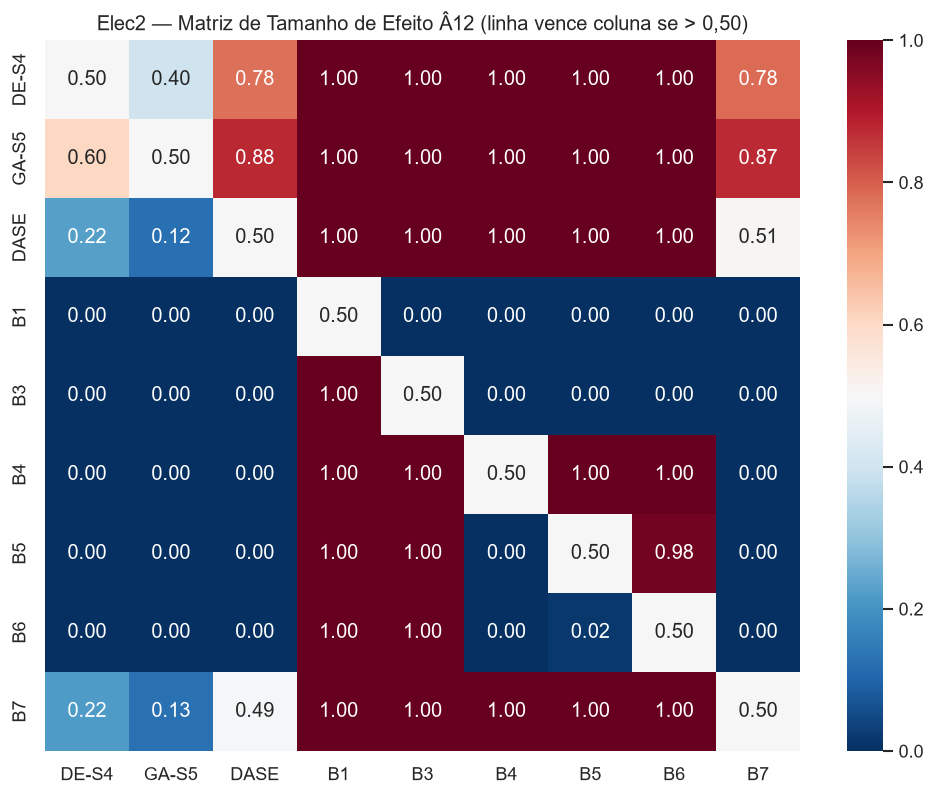

In [9]:
# Matriz Heatmap de tamanho de efeito Â12 entre os métodos principais (linha > coluna)
key_methods = list(dict.fromkeys(([best_de] if best_de else []) + ([best_ga] if best_ga else []) + extra_methods + baseline_methods + bench_methods))
for ds in real_datasets:
    sub_ds = core[core["dataset"] == ds].pivot_table(index="seed", columns="method", values="macro_f1")
    cols_ok = [m for m in key_methods if m in sub_ds.columns]
    mat = pd.DataFrame(index=cols_ok, columns=cols_ok, dtype=float)
    for a in cols_ok:
        for b in cols_ok:
            mat.loc[a, b] = 0.5 if a == b else a12(sub_ds[a].dropna(), sub_ds[b].dropna())
    fig, ax = plt.subplots(figsize=(8.5, 6.8))
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0.5, vmin=0.0, vmax=1.0, ax=ax)
    ax.set_title(f"{ds} — Matriz de Tamanho de Efeito Â12 (linha vence coluna se > 0,50)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"heatmap_a12_{ds}.png", dpi=150)
    plt.show()

## 4. Curvas Temporais nas Bases Reais

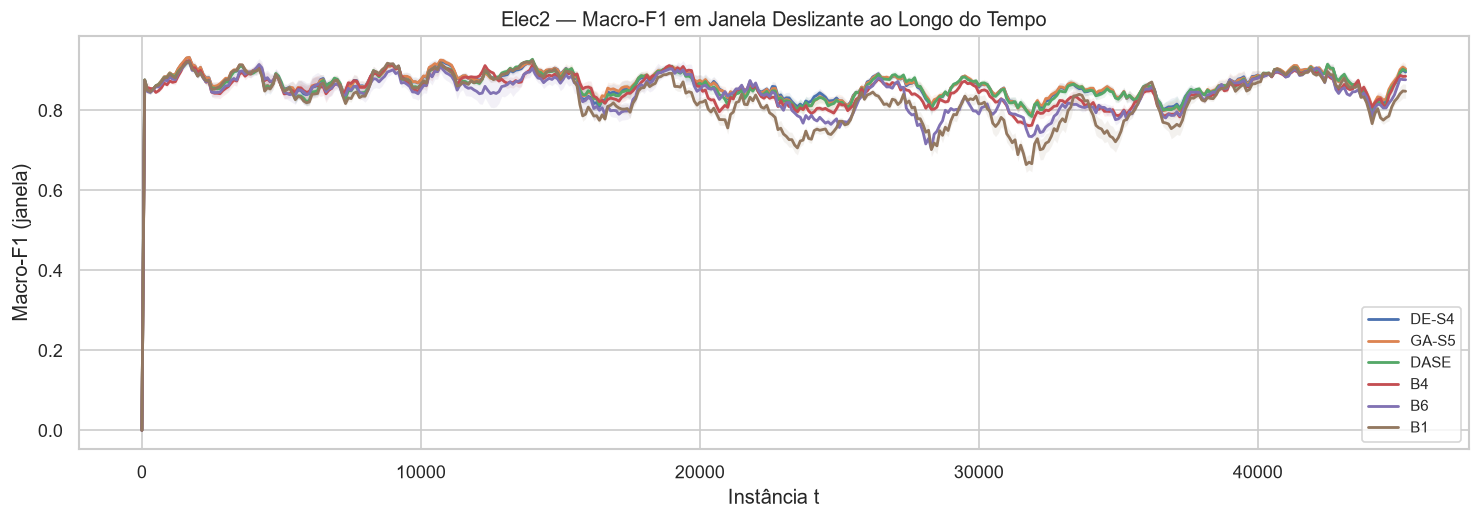

In [10]:
curve_methods = list(dict.fromkeys([m for m in [best_de, best_ga, "DETO", "DASE", "B4", "B6", "B1"] if m and m in mean_by_method.index]))
if len(curves) > 0 and curve_methods:
    for ds in real_datasets:
        fig, ax = plt.subplots(figsize=(12.5, 4.5))
        for m in curve_methods:
            arrs = [curves[k] for k in curves.files if k.startswith(f"{ds}|{m}|")]
            if not arrs:
                continue
            min_len = min(len(a) for a in arrs)
            mat = np.vstack([a[:min_len] for a in arrs])
            x = np.arange(min_len) * CURVE_STEP
            mu = mat.mean(axis=0)
            sd = mat.std(axis=0)
            ax.plot(x, mu, label=m, lw=1.7)
            ax.fill_between(x, mu - sd, mu + sd, alpha=0.10)
        ax.set_title(f"{ds} — Macro-F1 em Janela Deslizante ao Longo do Tempo")
        ax.set_xlabel("Instância t")
        ax.set_ylabel("Macro-F1 (janela)")
        ax.legend(fontsize=9, loc="lower right")
        fig.tight_layout()
        fig.savefig(FIG_DIR / f"curve_{ds}.png", dpi=150)
        plt.show()

## 5. Custo Computacional, Eventos de Drift e Convergência Pós-Drift

,macro_f1,n_events,n_detections,n_evals,gens_to_95,eval_size,replay_time_s,time_per_inst_ms
method,,,,,,,,
GA-S5,0.8704,10.1667,10.1667,8472.7333,14.6441,709.6520,0.7656,1.2408
GA-S2,0.8701,9.6667,9.6667,8116.1333,14.3833,632.4377,0.6763,1.2388
GA-S6,0.8700,10.4000,10.4000,8331.3333,13.8494,668.5775,0.7285,1.2400
GA-S3,0.8700,10.0667,10.0667,8552.8000,14.8962,663.5410,0.7429,1.2403
DE-S4,0.8694,10.3333,10.3333,9855.0000,15.8354,670.9438,0.9818,1.2456
DE-S3,0.8693,11.0667,11.0667,8231.0000,10.7448,637.0253,0.8040,1.2417
DE-S6,0.8692,10.9000,10.9000,8639.0000,12.2733,646.9410,0.8308,1.2423
GA-S4,0.8690,10.3333,10.3333,8656.0000,13.8468,649.1663,0.7421,1.2403
GA-S1,0.8687,10.3000,10.3000,8932.2000,15.6343,646.5221,0.7628,1.2408


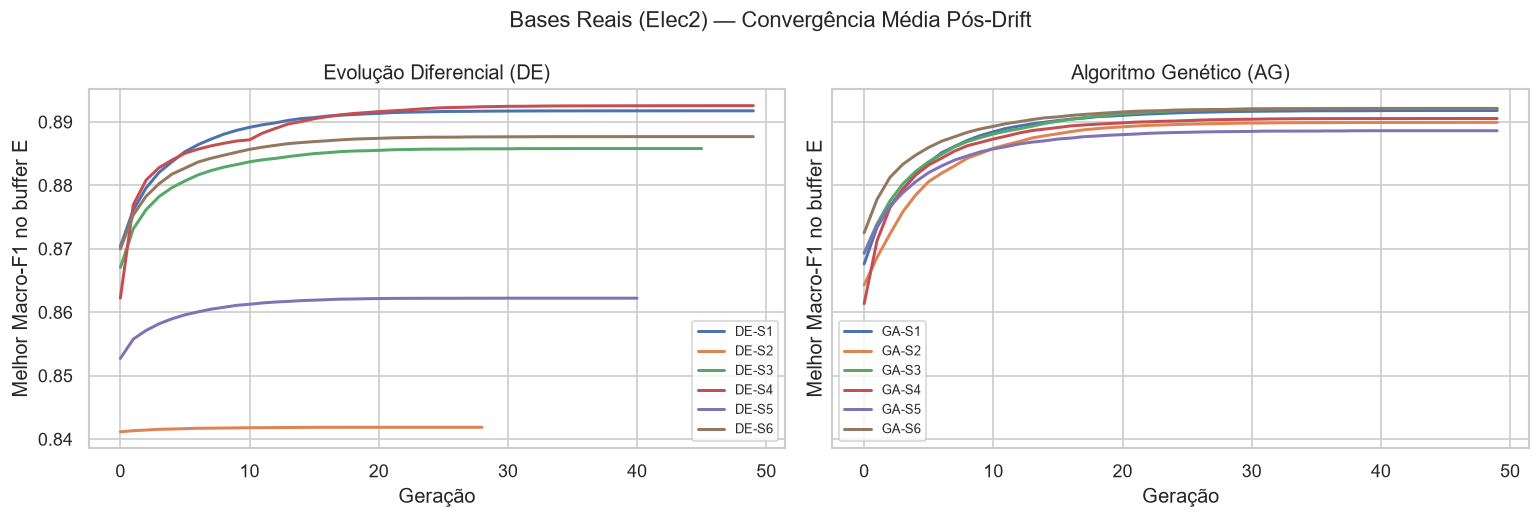

In [11]:
cost_cols = [c for c in [
    "macro_f1", "n_events", "n_detections", "n_evals", "gens_to_95", "eval_size", "replay_time_s", "time_per_inst_ms"
] if c in core.columns]
cost_summary = core.groupby("method")[cost_cols].mean().sort_values("macro_f1", ascending=False)
display(cost_summary.round(4))

if not events.empty and "history" in events.columns:
    post = events[(events["initial"] == False) & (events["method"].str.startswith(("DE-", "GA-")))].copy()
    if not post.empty:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
        for ax, prefix, title in zip(axes, ["DE-", "GA-"], ["Evolução Diferencial (DE)", "Algoritmo Genético (AG)"]):
            sub_ev = post[post["method"].str.startswith(prefix)]
            for m in sorted(sub_ev["method"].unique()):
                hists = [json.loads(h) for h in sub_ev[sub_ev["method"] == m]["history"] if h and h != "[]"]
                if not hists:
                    continue
                max_g = max(len(h) for h in hists)
                padded = np.array([h + [h[-1]] * (max_g - len(h)) for h in hists])
                ax.plot(padded.mean(axis=0), label=m, lw=1.8)
            ax.set_title(title)
            ax.set_xlabel("Geração")
            ax.set_ylabel("Melhor Macro-F1 no buffer E")
            ax.legend(fontsize=8)
        fig.suptitle(f"Bases Reais ({', '.join(real_datasets)}) — Convergência Média Pós-Drift", fontsize=13)
        fig.tight_layout()
        fig.savefig(FIG_DIR / "convergence_reais.png", dpi=150)
        plt.show()